# The chain, stage by stage

Notebook 01 ran the whole chain with one command; this one runs each stage from Python so
you can stop and look between them.

Raw probe file to a size distribution, in five steps, with no campaign data and no
MATLAB/Octave required. The synthetic input comes from `scripts/make_demo_flight.py`, which
hand-builds a raw `.2DS` file shaped like a real 2D-S recording -- the real record
geometry, the real housekeeping packet layout. This notebook builds the **dense** demo
flight (`--dense` on the command line), twelve particles per second, which is what the
documented CLI quickstart in `docs/02-user-guide.md` builds: the plain flight's
five particles all sit below the first used bin's lower edge, so its size distribution
plots as a flat line.

**This proves the pipe fits together, not that the science is right.** The demo particles
survive the image-processing stage's accept rules on purpose, but their inter-arrival times are arbitrary
constants, not a realistic clock. The oracle-backed validation the project's real fidelity
claims rest on is against archived field-campaign products (see
`docs/04-validation.md`), not this synthetic case.

**What this notebook is not: the supported command line.** The cells below call
`run_flight.py`'s stage functions directly, in-process, because that is what makes each
stage visible one cell at a time. Driving it that way selects the campaign preset by
calling `run_flight.use_preset` (cell below) rather than by passing `--preset`, and it
**bypasses the threshold-policy confirmation gate** that `run_flight.py`'s command line
puts in front of a run whose thresholds nobody chose for the campaign -- the gate that
`--yes` answers, documented in `docs/06-configuration.md`. The `.call` sidecar
is still written by every stage, so the outputs are stamped exactly as a CLI run's are.
For real data, run the command line:

```bash
.venv/Scripts/python.exe -m arrayprobe make-demo-flight --dense examples/start_here/output/base160101000000.2DS
.venv/Scripts/python.exe -m arrayprobe run examples/start_here/run.toml examples/start_here/output/base160101000000.2DS --yes
```

Run both from the repository root; `examples/start_here/README.md` walks through them.

**Before this:** [01_start_here](01_start_here.ipynb) (Start here: process one probe file and look at what came out). **Next:** [03_choosing_an_engine](03_choosing_an_engine.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

This run has nothing to compare its output against, so it shows only that the stages run;
checking output against an archived product is
[`01_validate_against_a_product.ipynb`](../3_validation/01_validate_against_a_product.ipynb).

## 1. Build a synthetic raw flight

First, a check that the notebook is running from the repository root, where the cells
below look for `scripts/` and `tests/data/`.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/1_getting_started/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

Next, load the two command-line tools as Python modules, choose the demo campaign's
settings and the v3.5 engine, and make a temporary folder for the outputs.

In [2]:
import sys
import tempfile
from pathlib import Path

sys.path.insert(0, "scripts")
import make_demo_flight  # noqa: E402
import run_flight  # noqa: E402

# The campaign call in force, by name -- the in-process equivalent of the CLI's
# `--preset DEMO_2DS_H`. Called before any path is built, because the output
# paths carry the preset's orientation.
run_flight.use_preset("DEMO_2DS_H")

tmp = tempfile.TemporaryDirectory()
out = Path(tmp.name)
# The public package runs the v3.5 engine: this sets engine, profile and a constant-TAS aircraft file.
run_flight.use_engine_35(out)

'<tmp>\\aircraft.cdf'

Now write the raw file: the dense demo flight, twelve synthetic particles per second for
five seconds.

In [3]:
# SPEC's base<YYMMDDhhmmss> convention -- any valid-looking date/time works,
# the demo data are synthetic regardless.
raw = out / "base160101000000.2DS"
# The DENSE flight -- `--dense` on the command line. 12 particles per second
# (disks, rings and bars) spread across used bins, so the size distribution in
# step 5 has something in it. `build_demo_flight` is the plain one-particle
# flight; it plots flat, because its particles are all below the first used
# bin's lower edge (0.055 mm).
make_demo_flight.build_dense_demo_flight(raw, n_seconds=5)
print(f"raw file: {raw.name}, {raw.stat().st_size:,} bytes")

raw file: base160101000000.2DS, 41,140 bytes


## 2. Decode: raw → a per-record netCDF

This is `run_flight.py`'s own stage function, the same one `run_flight.py --preset
DEMO_2DS_H --engine 3.5 --stages 2` calls -- it writes, beside the decoded file, the airspeed file the
size-distribution stage needs. For the general, no-preset entry point (every fidelity-sensitive argument
required explicitly), see `arrayprobe run <config.toml>` with `[run].engine = "3.5"` and `[run].stages = "2"`.

In [4]:
run_flight.log = lambda *a, **kw: None  # quiet the tool's own progress prints

image = run_flight.stage2(raw, out)
print(f"decoded: {image.name}")

decoded: base160101000000.H.nc


## 3. Frame particles: decoded → a per-particle proc file

`imgProc_sm`'s port: every particle in the record gets sized, classified by habit, and
given a reject code.

In [5]:
proc = run_flight.stage3(image, out)
print(f"proc: {proc.name}")

proc: proc.base160101000000.H.nc


## 4. Size distribution: proc → one-second bins

`sizeDist`'s port: accepted particles are binned into a one-second particle size
distribution, with the used-bin convention documented in `docs/02-user-guide.md`.

In [6]:
sd = run_flight.stage4(proc, raw.stem, out)
print(f"sd: {sd.name}")

sd: sd.base160101000000.H.nc


## 5. Plot the size distribution

`conc_minR` is `(time, bin)` -- concentration per diameter bin, per second. Summing over
time gives a whole-flight PSD shape; a real flight would read this over thousands of
seconds, not four.

**What you should see.** Not a flat line: **ten** bins carry a non-zero summed
concentration, spread from 0.06 to 0.41 mm (measured on this exact chain, v3.5
engine). 60 particles decode and all 60 are accepted; **48** land in used bins. 40 carry the
clean code `0` and 20 are recognised as hollow and kept: `H` (10) with the Korolev size
correction, `h` (10) with no hole edge to correct from. Stock v3.5 runs the hollow test;
some field-campaign configurations switch it off. The plot is a real distribution
and a thin one: enough to see the pipeline produce a shape and to watch a threshold
move it, and nowhere near enough to look like a cloud. If your plot is flat, the flight
was built with `build_demo_flight` rather than `build_dense_demo_flight` -- that is the
one difference, not a broken install.

17 of 128 size ranges hold particles


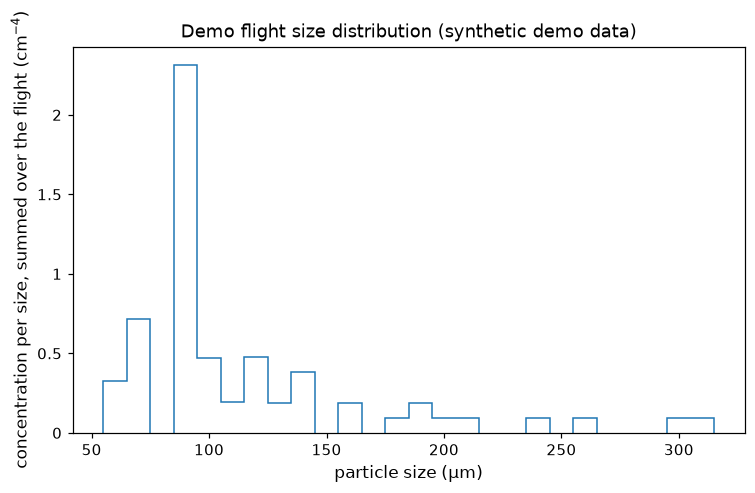

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import xarray as xr

plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
                     "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10})

# Raw stored values (mask_and_scale=False), as the file holds them.
with xr.open_dataset(sd, mask_and_scale=False, decode_times=False) as ds:
    conc = ds["conc_minR"].values
    bin_mid = ds["bin_mid"].values
    edges = np.append(ds["bin_min"].values, ds["bin_max"].values[-1])   # bin edges, for the steps
    size_units = ds["bin_mid"].attrs.get("units", "mm")
    conc_units = ds["conc_minR"].attrs.get("units", "")

psd = np.nansum(np.nan_to_num(conc), axis=0)

def unit_text(u):
    """'cm-4' -> cm$^{-4}$ for axis labels; the stored attribute is not changed."""
    base, _, power = str(u).partition("-")
    return f"{base}$^{{-{power}}}$" if power.isdigit() else str(u)

# Display only: sizes drawn in µm when the file stores mm; the data are unchanged.
scale = 1000.0 if size_units in ("mm", "millimeter") else 1.0
size_shown, edges_shown = bin_mid * scale, edges * scale
size_label = "µm" if scale == 1000.0 else size_units
held = psd > 0
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.stairs(np.where(held, psd, np.nan), edges_shown)   # one step per size range
lo, hi = edges_shown[:-1][held].min(), edges_shown[1:][held].max()
span = hi - lo
ax.set_xlim(lo - 0.05 * span, hi + 0.05 * span)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel(f"particle size ({size_label})")
ax.set_ylabel(f"concentration per size, summed over the flight ({unit_text(conc_units)})")
ax.set_title("Demo flight size distribution (synthetic demo data)")
fig.tight_layout()
plt.show()
print(f"{int(held.sum())} of {bin_mid.size} size ranges hold particles")

*Figure 1. Size distribution of the synthetic demo flight, each size range's concentration summed over every second of the flight, zoomed to the size ranges that hold particles; each dot is one size range.*

## Where to go next

- [`06_read_products.ipynb`](06_read_products.ipynb) -- opening `proc`/`sd` files directly, the variable contract,
  the `.call` sidecar.
- [`01_validate_against_a_product.ipynb`](../3_validation/01_validate_against_a_product.ipynb) -- comparing a port output against an archived
  reference product.
- `docs/02-user-guide.md` -- the general per-stage CLI, with every
  fidelity-sensitive argument explicit.